# 04 EDA – próba tygodniowa

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import APA_STYLE, CYCLES, PHASE_ORDER, POLITICAL_SUBREDDITS, PROCESSED_DIR, SUBREDDITS

EDA_DIR = PROCESSED_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(APA_STYLE)
plt.rcParams.update({"figure.dpi": 110})
political_labels = [f"{subreddit} {cycle}" for subreddit in POLITICAL_SUBREDDITS for cycle in CYCLES]


def draw_heatmap(ax, table, fmt, cmap, vmax=None):
    """Mapa cieplna z liczbami w komórkach (wiersze = indeks tabeli, kolumny = kolumny tabeli)."""
    values = table.to_numpy(dtype=float)
    vmax = vmax or np.nanmax(values)
    image = ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), [str(column) for column in table.columns], rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), [str(index) for index in table.index])
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            if not np.isnan(values[row, column]):
                ax.text(column, row, fmt.format(values[row, column]), ha="center", va="center", fontsize=7,
                        color="white" if values[row, column] > 0.6 * vmax else "black")
    return image

## 2. Wczytanie próby

In [2]:
sample = pd.read_parquet(PROCESSED_DIR / "sample.parquet", columns=["id", "link_id", "subreddit", "cycle", "week_start", "phase", "n_words"])
sample.shape

(794519, 7)

## 3. Liczebność próby

In [3]:
size_by_group = sample.groupby(["subreddit", "cycle"]).agg(n=("id", "size"), n_weeks=("week_start", "nunique"), n_threads=("link_id", "nunique"))
size_by_group["comments_per_thread"] = size_by_group["n"] / size_by_group["n_threads"]
size_by_group.to_csv(EDA_DIR / "sample_size.csv")
counts = size_by_group["n"].unstack("cycle").reindex(list(SUBREDDITS))
counts["razem"] = counts.sum(axis=1)
counts.loc["razem"] = counts.sum()
counts.astype("Int64")

cycle,2012,2014,2016,2018,2020,2022,2024,razem
subreddit,,,,,,,,
democrats,11519,<NA>,30285,<NA>,31500,<NA>,31200,104504
Liberal,16851,<NA>,30478,<NA>,29924,<NA>,30867,108120
Republican,24002,<NA>,30891,<NA>,31128,<NA>,31200,117221
Conservative,31000,<NA>,31500,<NA>,31500,<NA>,31200,125200
running,31200,15900,31500,15900,31500,15900,31200,173100
languagelearning,24474,15900,31500,15900,31500,15900,31200,166374
razem,139046,31800,186154,31800,187052,31800,186867,794519


**Liczebność próby**

- Próba ma 794 519 komentarzy: 139 046 w cyklu 2012, 186 154 w 2016, 187 052 w 2020 i 186 867 w 2024 oraz po 31 800 w latach 2014, 2018 i 2022.
- Plik z pełnym limitem ma 31 200 (104 tygodnie) lub 31 500 komentarzy (105 tygodni). Najmniej mają r/democrats 2012 (11 519), r/Liberal 2012 (16 851)
  i r/Republican 2012 (24 002).
- Komentarzy na wątek jest najwięcej w r/Liberal 2020 i 2024 (9,6 i 10,3), a najmniej w r/Conservative (1,6–3,4).

Komentarze z jednego wątku nie są niezależne. W r/Liberal 2020 i 2024 próba pochodzi z ok. 3 000 wątków, więc jest bardziej skupiona niż w pozostałych subredditach.

## 4. Liczebność według fazy (subreddity polityczne)

In [4]:
weekly_sizes = sample.groupby(["subreddit", "cycle", "week_start"], as_index=False).agg(n=("id", "size"), phase=("phase", "first"))
phase_sizes = weekly_sizes.groupby(["subreddit", "cycle", "phase"], dropna=False).agg(
    n_weeks=("n", "size"), n_comments=("n", "sum"), median=("n", "median"), minimum=("n", "min"))
phase_sizes.to_csv(EDA_DIR / "sample_phase_sizes.csv")
political_phase = phase_sizes.loc[POLITICAL_SUBREDDITS].reset_index()
political_phase["file"] = political_phase["subreddit"] + " " + political_phase["cycle"].astype(str)
comments = political_phase.pivot_table(index="file", columns="phase", values="n_comments")[PHASE_ORDER].reindex(political_labels)
comments

phase,bazowa,przedwyborcza,szczytowa,przejsciowa,powyborcza
file,,,,,
democrats 2012,375.0,5769.0,1810.0,1848.0,1717.0
democrats 2016,5045.0,14656.0,4584.0,3300.0,2400.0
democrats 2020,4200.0,18300.0,3000.0,3300.0,2400.0
democrats 2024,6600.0,15600.0,3300.0,3300.0,2400.0
Liberal 2012,350.0,9025.0,2044.0,3032.0,2400.0
Liberal 2016,5611.0,14885.0,4062.0,3300.0,2320.0
Liberal 2020,4021.0,17021.0,3000.0,3182.0,2400.0
Liberal 2024,6595.0,15410.0,3162.0,3300.0,2400.0
Republican 2012,727.0,14875.0,2700.0,3300.0,2400.0


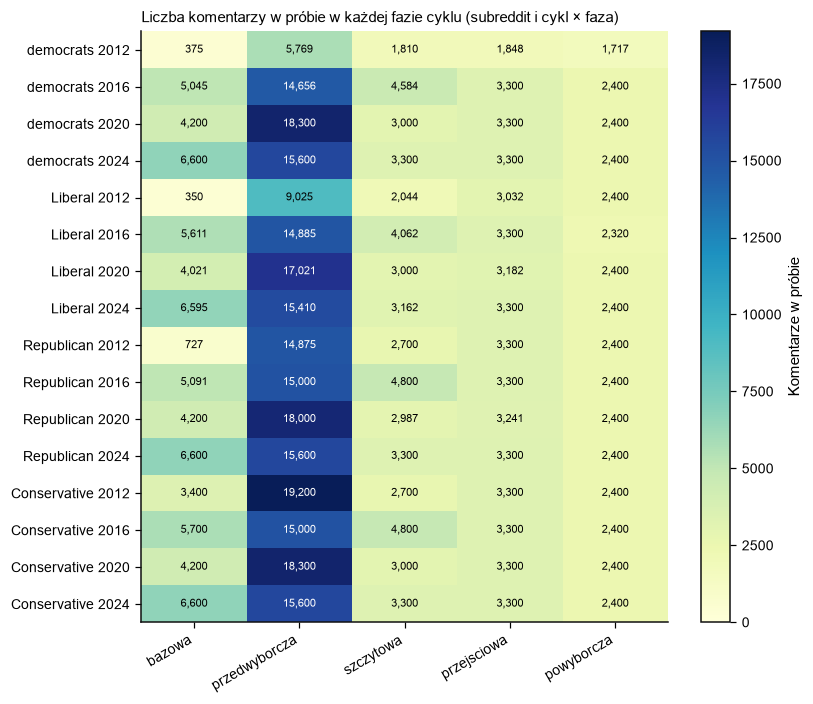

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
image = draw_heatmap(ax, comments, "{:,.0f}", "YlGnBu")
ax.set_title("Liczba komentarzy w próbie w każdej fazie cyklu (subreddit i cykl × faza)", loc="left")
fig.colorbar(image, ax=ax, label="Komentarze w próbie")
plt.tight_layout()
plt.show()

**Jak czytać**
- Wiersz to subreddit w jednym cyklu, kolumna to faza. Liczba w komórce to liczba komentarzy z próby w tej fazie. Ciemniejszy kolor to więcej komentarzy.

**Co widać**
- W 2016–2024 każda komórka subreddit × faza ma co najmniej 2 320 komentarzy. Faza powyborcza to zwykle 2 400 (8 tygodni × 300), a przejściowa 3 300 (11 × 300).
- Najmniejsze komórki to faza bazowa 2012: r/Liberal 350, r/democrats 375 i r/Republican 727 komentarzy.
- Najmniejsza komórka fazy szczytowej to r/democrats 2012 (1 810), a fazy przejściowej r/democrats 2012 (1 848).
- Fazy różnią się liczebnością głównie przez liczbę tygodni (od 8 w powyborczej do 64 w przedwyborczej), a w 2012 także przez mało komentarzy w tygodniu.

## 5. Długość komentarzy w próbie

In [6]:
sample["below_10w"] = sample["n_words"] < 10
grouped = sample.groupby(["subreddit", "cycle"])
length = pd.DataFrame({"median": grouped["n_words"].median(), "p25": grouped["n_words"].quantile(0.25),
                       "p75": grouped["n_words"].quantile(0.75), "share_below_10w": grouped["below_10w"].mean(),
                       "n_at_least_10w": grouped.size() - grouped["below_10w"].sum()})
length.to_csv(EDA_DIR / "sample_length.csv")
length.round(2)

median   p25   p75  share_below_10w  n_at_least_10w
subreddit        cycle                                                     
Conservative     2012     28.0  14.0  57.0             0.13           27021
                 2016     24.0  13.0  48.0             0.15           26691
                 2020     21.0  11.0  41.0             0.18           25760
                 2024     20.0  11.0  37.0             0.19           25204
Liberal          2012     27.0  14.0  59.0             0.14           14494
                 2016     27.0  14.0  55.0             0.14           26271
                 2020     22.0  12.0  44.0             0.18           24604
                 2024     23.0  12.0  45.0             0.17           25699
Republican       2012     30.0  15.0  62.0             0.12           21051
                 2016     27.0  14.0  52.0             0.13           26841
                 2020     21.0  11.0  40.0             0.20           24988
                 2024     19.0  11.0  37.0             0.20           24937
democrats        2012     26.0  14.0  55.0             0.14            9895
                 2016     23.0  12.0  48.0             0.17           25235
                 2020     20.0  11.0  38.0             0.20           25218
                 2024     19.0  11.0  36.0             0.21           24710
languagelearning 2012     33.0  16.0  65.0             0.12           21619
                 2014     31.0  15.0  63.0             0.12           13947
                 2016     32.0  16.0  66.0             0.12           27683
                 2018     31.0  15.0  65.0             0.13           13867
                 2020     31.0  15.0  64.0             0.14           27175
                 2022     33.0  16.0  68.0             0.12           13980
                 2024     32.0  16.0  65.0             0.12           27305
running          2012     30.0  15.0  56.0             0.12           27373
                 2014     31.0  16.0  58.0             0.11           14114
                 2016     31.0  16.0  57.0             0.11           27932
                 2018     33.0  17.0  61.0             0.11           14228
                 2020     34.0  18.0  64.0             0.10           28423
                 2022     33.0  17.0  61.0             0.10           14289
                 2024     35.0  18.0  64.0             0.09           28346

**Długość komentarzy w próbie**

- Próba zawiera tylko komentarze ≥ 5 słów, więc mediany są wyższe niż w `eda/03`. W subredditach politycznych mediana spada z 26–30 słów w 2012
  do 19–23 w 2024, a udział komentarzy < 10 słów rośnie z 12–14% do 17–21%.
- W subredditach odniesienia długość jest stała: r/running 30–35 słów, r/languagelearning 31–33, komentarzy < 10 słów 9–14%.
- Podzbiór ≥ 10 słów do analizy wrażliwości ma w plikach politycznych 2016–2024 po ok. 24 600–26 800 komentarzy, a w 2012 od 9 895 (r/democrats) do 27 021 (r/Conservative).

Próg 10 słów zmniejsza próbę polityczną o 17–21% w 2020 i 2024 oraz o 12–14% w 2012, więc w późniejszych cyklach usuwa jej nieco większą część.